In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import seaborn as sns

In [2]:
df = pd.read_csv('/content/class_ipl_22-26_dataset.csv')

In [3]:
shape=df.shape
print('Rows:',shape[0])
print('Columns:',shape[1])

Rows: 367
Columns: 25


In [11]:
column ='team1_runs'
df[column].describe()

,team1_runs
count,367.000000
mean,185.070845
std,36.516265
min,25.000000
25%,161.500000
50%,187.000000
75%,209.000000
max,287.000000


# Z- Score

In [13]:
scaler = StandardScaler()
df['z_score'] =scaler.fit_transform(df[[column]])
df[[column,'z_score']].head(10)


,team1_runs,z_score
0,131,-1.482755
1,177,-0.221322
2,205,0.546506
3,158,-0.742349
4,210,0.683618
5,128,-1.565022
6,210,0.683618
7,137,-1.318220
8,171,-0.385857
9,193,0.217437


In [15]:
#DETECT OUTLIER
outlier = df[abs(df['z_score'])>3]
print('Number of Outlier:',len(outlier))
outlier[[column,'z_score']].head()

Number of Outlier: 3


,team1_runs,z_score
34,68,-3.210369
304,25,-4.389534
331,75,-3.018411


In [17]:
# REMOVE OURLIER

clean_df =df[abs(df['z_score'])<=3]
print('original rows:',len(df))
print('Clean Rows:',len(clean_df))
clean_df[[column,'z_score']].head()

original rows: 367
Clean Rows: 364


,team1_runs,z_score
0,131,-1.482755
1,177,-0.221322
2,205,0.546506
3,158,-0.742349
4,210,0.683618


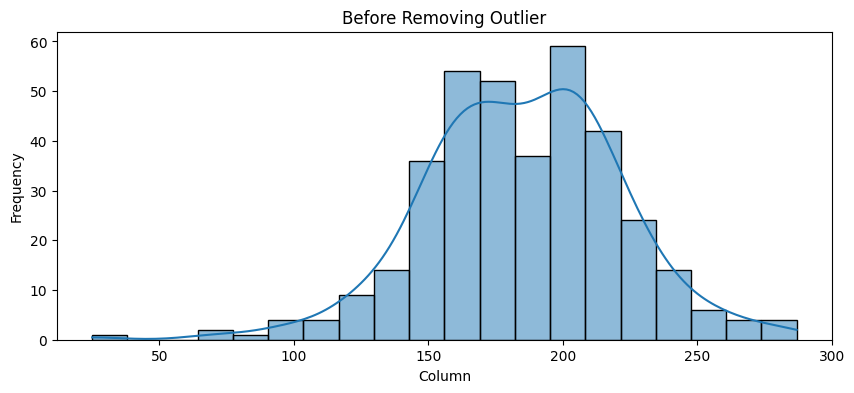

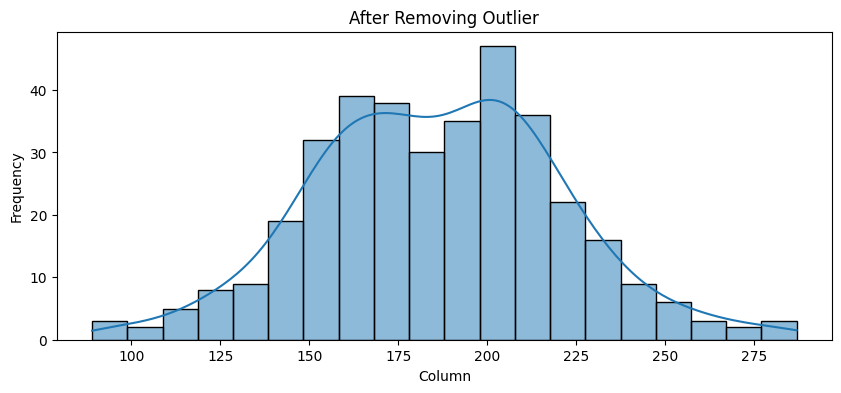

In [19]:
plt.figure(figsize=(10,4))
sns.histplot(df[column],kde=True,bins=20)
plt.xlabel('Column')
plt.ylabel('Frequency')
plt.title('Before Removing Outlier')
plt.show()

plt.figure(figsize=(10,4))
sns.histplot(clean_df[column],kde=True,bins=20)
plt.xlabel('Column')
plt.ylabel('Frequency')
plt.title('After Removing Outlier')
plt.show()